# NB04 — Transformer Causal (Décodeur-only) et Entraînement
> **Projet 1.1 — Phase C & D** : Vaswani et al. 2017, Radford et al. 2019 (GPT-2), Xiong et al. 2020 (Pre-LN).

| | Chemin |
|---|---|
| **Entrées** | `data/processed/<DATA_VERSION>/{train.csv, val.csv}` (produits par NB02) |
| **Sorties** | `models/transformer-notebook/best.pt`, `results/runs/transformer-notebook/history.csv` |

Ce notebook implémente et entraîne l'architecture cible principale du projet :
1. **Transformer Causal (Pre-LN)** avec embeddings de position appris (200 positions) et Weight Tying (`head.weight = token_embed.weight`).
2. **Initialisation style GPT-2** (`std=0.02`) pour garantir une loss initiale saine (~ln(23) ≈ 3.14 nats au lieu de 47).
3. **Test unitaire de causalité** : vérifie que le futur ne peut jamais fuiter dans le passé.
4. **Entraînement avec scheduler** : warmup linéaire (100 pas) + décroissance en cosinus, AdamW, gradient clipping.
5. **Support de la précision mixte (AMP float16)** sur GPU Colab.
6. **Courbes d'apprentissage & comparaison** : comparaison directe avec le Bigramme et le LSTM.
7. **Génération autorégressive exacte** : greedy, température, top-k et nucleus sampling (`sampling.py`).


In [1]:
# ==============================================================================
# Cellule 1 : RÉGLAGES + Bootstrap (local ET Google Colab), Drive, chemins, imports
# ==============================================================================
# ------------------------------ RÉGLAGES -------------------------------------
# Nom du jeu de données (dossier data/processed/<nom>/)
#   None -> automatique : 'toy' en local, 'SRR3544218' ou 'v1' sur Colab.
DATA_VERSION_OVERRIDE = None

# Hyperparamètres
SEED = 42
BATCH_SIZE = 64
EMBED_DIM = 128
NUM_HEADS = 4
NUM_LAYERS = 4
DIM_FEEDFORWARD = 512
DROPOUT = 0.1
LR = 6e-4
WEIGHT_DECAY = 0.01
EPOCHS = 15
GRAD_CLIP = 1.0
WARMUP = 100
PATIENCE = 3
USE_AMP = True
# ------------------------------------------------------------------------------
import os, sys, json, math, time, subprocess
from pathlib import Path

REPO_URL = "https://github.com/AhmadBelhaj4/Recherche_AI.git"
BRANCH = "b/sprint2-training"


def _find_root(start):
    """Remonte depuis `start` jusqu'au dossier qui contient utils.py et models.py."""
    start = Path(start).resolve()
    for p in [start, *start.parents]:
        if (p / "utils.py").exists() and (p / "models.py").exists():
            return p
        if (p / "project1" / "utils.py").exists():
            return p / "project1"
    return None


try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

ROOT_DIR = _find_root(Path.cwd())

if ROOT_DIR is None and IN_COLAB:
    clone_target = Path("/content/Recherche_AI")
    if not clone_target.exists():
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(clone_target)], check=True)
    ROOT_DIR = _find_root(clone_target)

if ROOT_DIR is None:
    raise FileNotFoundError("utils.py introuvable : ouvrez le notebook dans le dépôt Recherche_AI.")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    _drive = Path("/content/drive/MyDrive/AI_Project_Shared")
    if not _drive.exists():
        raise FileNotFoundError(f"Dossier Drive introuvable : {_drive}. Ajoutez le raccourci dans 'Mon Drive'.")
    os.environ.setdefault("AI_PROJECT_DIR", str(_drive))

sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from utils import (get_paths, get_data_version, get_device, set_seed,
                   AminoAcidTokenizer, make_loader, shift, compute_nats_and_perplexity,
                   VOCAB_SIZE, PAD_ID, BOS_ID, EOS_ID, is_valid_sequence)
from models import CausalTransformerLM
from training import evaluate, lr_at, count_params, load_split
from sampling import generate

set_seed(SEED)
device = get_device()
PATHS = get_paths()
DATA_VERSION = DATA_VERSION_OVERRIDE or get_data_version()
DATA_DIR = PATHS["processed"] / DATA_VERSION

print(f"MODE         : {'DONNÉES RÉELLES (Colab / Drive)' if DATA_VERSION != 'toy' else 'TOY (local, fausses données)'}")
print(f"DATA_VERSION : {DATA_VERSION}")
print(f"Dossier data : {DATA_DIR}")
print(f"Device       : {device}")
print(f"Seed: {SEED} | Layers: {NUM_LAYERS} | Heads: {NUM_HEADS} | D_model: {EMBED_DIM} | LR: {LR}")


MODE         : TOY (local, fausses données)
DATA_VERSION : toy
Dossier data : C:\Users\GMI\Desktop\My_Projects\reacherche_ai\data\toy\processed\toy
Device       : cpu
Seed: 42 | Layers: 4 | Heads: 4 | D_model: 128 | LR: 0.0006


## 2. Architecture Transformer Causal et Test Unitaire du Masque
Le décodeur utilise `norm_first=True` (Pre-LN) pour une meilleure stabilité d'entraînement, et un masque triangulaire causal strict :
$M_{ij} = -\infty$ pour $j > i$.
Le test ci-dessous garantit que modifier un token futur ne change absolument rien aux prédictions des positions précédentes.


In [2]:
# ==============================================================================
# Cellule 2 : Instanciation et Test Unitaire de Causalité
# ==============================================================================
model = CausalTransformerLM(VOCAB_SIZE, EMBED_DIM, NUM_HEADS, NUM_LAYERS,
                            DIM_FEEDFORWARD, max_len=200, dropout=DROPOUT).to(device)
n_params = count_params(model)
print(f"Transformer instancié sur {device} : {n_params:,} paramètres entraînables.")

# Test de non-violation de la causalité
model.eval()
with torch.no_grad():
    x1 = torch.tensor([[BOS_ID, 5, 8, 12]], device=device)
    x2 = torch.tensor([[BOS_ID, 5, 8, 20]], device=device)  # 4ème token différent
    logits1 = model(x1)
    logits2 = model(x2)
    diff = (logits1[:, :3, :] - logits2[:, :3, :]).abs().max().item()

print(f"Différence maximale sur les prédictions passées : {diff:.6e}")
assert diff < 1e-5, "ÉCHEC : Violation de la causalité !"
print("✅ Test unitaire de causalité validé avec succès (le futur ne fuite pas).")


Transformer instancié sur cpu : 821,888 paramètres entraînables.
Différence maximale sur les prédictions passées : 0.000000e+00
✅ Test unitaire de causalité validé avec succès (le futur ne fuite pas).


## 3. Chargement des Données (Train & Validation)
Lecture de `data/processed/<DATA_VERSION>/train.csv` et `val.csv`.


In [3]:
# ==============================================================================
# Cellule 3 : Chargement des données et DataLoaders
# ==============================================================================
train_path = DATA_DIR / "train.csv"
val_path = DATA_DIR / "val.csv"

# Auto-génération en mode toy si nécessaire
if (not train_path.exists() or not val_path.exists()) and DATA_VERSION == "toy":
    print("Génération automatique des données toy...")
    subprocess.run([sys.executable, str(ROOT_DIR / "scripts" / "make_toy_data.py")], check=True)

train_seqs = load_split(DATA_VERSION, "train")
val_seqs = load_split(DATA_VERSION, "val")

tok = AminoAcidTokenizer()
train_loader = make_loader(train_seqs, tok, batch_size=BATCH_SIZE, shuffle=True, seed=SEED)
val_loader = make_loader(val_seqs, tok, batch_size=BATCH_SIZE, shuffle=False)

print(f"Données prêtes ({DATA_VERSION}) :")
print(f"- Train : {len(train_seqs):,} séquences ({len(train_loader)} batchs)")
print(f"- Val   : {len(val_seqs):,} séquences ({len(val_loader)} batchs)")


Données prêtes (toy) :
- Train : 180 séquences (3 batchs)
- Val   : 10 séquences (1 batchs)


## 4. Entraînement du Transformer Causal avec Warmup & AMP
- **Warmup + Cosine Decay** : montée en douceur du taux d'apprentissage sur 100 pas, puis décroissance cosinusoïdale.
- **AMP (Automated Mixed Precision)** : activé automatiquement sur GPU pour doubler le débit de calcul.
- **Gradient Clipping** : 1.0 sur les vrais gradients après dé-normalisation du scaler.


In [4]:
# ==============================================================================
# Cellule 4 : Boucle d'entraînement du Transformer
# ==============================================================================
RUN_ID = f"transformer-notebook-{DATA_VERSION}"
ckpt_dir = PATHS["models"] / RUN_ID
res_dir = PATHS["results"] / "runs" / RUN_ID
ckpt_dir.mkdir(parents=True, exist_ok=True)
res_dir.mkdir(parents=True, exist_ok=True)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
crit = nn.CrossEntropyLoss(ignore_index=PAD_ID, reduction="sum")
amp_enabled = bool(USE_AMP and device.type == "cuda")
scaler = torch.amp.GradScaler(device.type, enabled=amp_enabled)
total_steps = EPOCHS * len(train_loader)

history = []
best_val_nats = float("inf")
best_epoch = 0
best_path = ckpt_dir / "best.pt"

print(f"Début de l'entraînement Transformer ({EPOCHS} époques, AMP={amp_enabled})...")
t_start = time.time()
step = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    t0 = time.time()
    tot_loss, tot_tokens = 0.0, 0
    for batch in train_loader:
        x, y = shift(batch)
        x, y = x.to(device), y.to(device)
        current_lr = lr_at(step, total_steps, LR, WARMUP)
        for g in opt.param_groups:
            g["lr"] = current_lr
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
            logits = model(x)
        loss_sum = crit(logits.float().reshape(-1, VOCAB_SIZE), y.reshape(-1))
        n = (y != PAD_ID).sum()
        loss = loss_sum / n.clamp(min=1)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(opt)
        scaler.update()
        tot_loss += loss_sum.item()
        tot_tokens += n.item()
        step += 1

    train_nats, train_ppl = compute_nats_and_perplexity(tot_loss, tot_tokens)
    val_nats, val_ppl = evaluate(model, val_loader, device)
    elapsed = time.time() - t0
    
    improved = val_nats < best_val_nats
    if improved:
        best_val_nats = val_nats
        best_epoch = epoch
        torch.save({
            "state_dict": model.state_dict(),
            "config": dict(model="transformer", embed_dim=EMBED_DIM, num_heads=NUM_HEADS,
                           num_layers=NUM_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=DROPOUT),
            "epoch": epoch,
            "val_nats": val_nats
        }, best_path)
    
    history.append({
        "epoch": epoch, "train_nats": train_nats, "train_ppl": train_ppl,
        "val_nats": val_nats, "val_ppl": val_ppl, "lr": current_lr, "seconds": elapsed
    })
    
    star = "★" if improved else ""
    print(f"Epoch {epoch:2d}/{EPOCHS} | Train {train_nats:.4f} (ppl {train_ppl:.2f}) | Val {val_nats:.4f} (ppl {val_ppl:.2f}) {star} | {elapsed:.1f}s")

pd.DataFrame(history).to_csv(res_dir / "history.csv", index=False)
print(f"\n✅ Entraînement terminé en {time.time() - t_start:.1f}s.")
print(f"Meilleur modèle sauvegardé dans {best_path} (epoch {best_epoch}, val nats {best_val_nats:.4f}, ppl {math.exp(best_val_nats):.2f})")


Début de l'entraînement Transformer (15 époques, AMP=False)...
Epoch  1/15 | Train 3.1510 (ppl 23.36) | Val 3.1480 (ppl 23.29) ★ | 4.9s
Epoch  2/15 | Train 3.1387 (ppl 23.07) | Val 3.1254 (ppl 22.77) ★ | 4.7s
Epoch  3/15 | Train 3.1178 (ppl 22.60) | Val 3.1007 (ppl 22.21) ★ | 4.8s
Epoch  4/15 | Train 3.0968 (ppl 22.13) | Val 3.0819 (ppl 21.80) ★ | 4.7s
Epoch  5/15 | Train 3.0822 (ppl 21.81) | Val 3.0692 (ppl 21.52) ★ | 4.7s
Epoch  6/15 | Train 3.0708 (ppl 21.56) | Val 3.0603 (ppl 21.33) ★ | 4.6s
Epoch  7/15 | Train 3.0619 (ppl 21.37) | Val 3.0538 (ppl 21.19) ★ | 4.9s
Epoch  8/15 | Train 3.0547 (ppl 21.21) | Val 3.0490 (ppl 21.09) ★ | 4.7s
Epoch  9/15 | Train 3.0480 (ppl 21.07) | Val 3.0449 (ppl 21.01) ★ | 4.8s
Epoch 10/15 | Train 3.0432 (ppl 20.97) | Val 3.0410 (ppl 20.93) ★ | 5.2s
Epoch 11/15 | Train 3.0390 (ppl 20.88) | Val 3.0375 (ppl 20.85) ★ | 5.2s
Epoch 12/15 | Train 3.0363 (ppl 20.83) | Val 3.0346 (ppl 20.79) ★ | 5.0s
Epoch 13/15 | Train 3.0338 (ppl 20.78) | Val 3.0320 (ppl 20.7

## 5. Visualisation des Courbes d'Apprentissage
Tracé de l'évolution de la perte en nats/token au fil des époques.


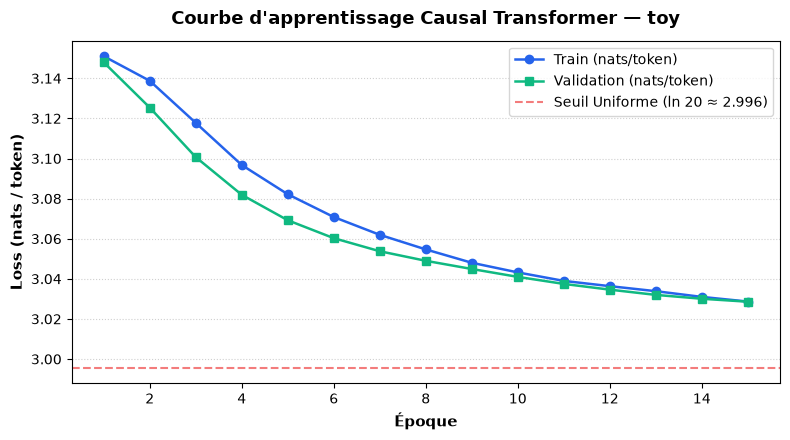

In [5]:
# ==============================================================================
# Cellule 5 : Courbes d'apprentissage Transformer
# ==============================================================================
epochs_range = [h["epoch"] for h in history]
train_curve = [h["train_nats"] for h in history]
val_curve = [h["val_nats"] for h in history]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(epochs_range, train_curve, marker="o", label="Train (nats/token)", color="#2563eb", linewidth=1.8)
ax.plot(epochs_range, val_curve, marker="s", label="Validation (nats/token)", color="#10b981", linewidth=1.8)
ax.axhline(math.log(20), color="#ef4444", linestyle="--", alpha=0.7, label=f"Seuil Uniforme (ln 20 ≈ {math.log(20):.3f})")
ax.set_xlabel("Époque", fontsize=11, fontweight="bold")
ax.set_ylabel("Loss (nats / token)", fontsize=11, fontweight="bold")
ax.set_title(f"Courbe d'apprentissage Causal Transformer — {DATA_VERSION}", fontsize=13, fontweight="bold", pad=12)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


## 6. Génération et Comparaison de Stratégies d'Échantillonnage
Échantillonnage de séquences d'anticorps VHH depuis `<BOS>` jusqu'à `<EOS>` avec le meilleur modèle sauvegardé :
1. **Échantillonnage Greedy** (argmax déterministe)
2. **Température $T=1.0$** (échantillonnage standard)
3. **Nucléus (Top-p = 0.95)**


In [6]:
# ==============================================================================
# Cellule 6 : Génération et échantillonnage
# ==============================================================================
print(f"Rechargement du meilleur checkpoint : {best_path}...")
ck = torch.load(best_path, map_location=device)
model.load_state_dict(ck["state_dict"])
model.eval()

print("1. Échantillonnage Greedy (argmax) :")
seqs_greedy, _ = generate(model, 3, device, max_len=140, greedy=True)
for i, s in enumerate(seqs_greedy, 1):
    print(f"  [{i}] L={len(s):>3} aa : {s[:65]}...")

print("\n2. Échantillonnage Température T=1.0 (seed=42) :")
seqs_t1, done_t1 = generate(model, 5, device, max_len=140, temperature=1.0, seed=SEED)
for i, (s, d) in enumerate(zip(seqs_t1, done_t1), 1):
    valid = is_valid_sequence(s) if s else False
    status = "✅ Valide" if valid else "⚠️ Invalide"
    eos_info = "EOS" if d else "Tronquée"
    print(f"  [{i}] {status} ({eos_info}) | L={len(s):>3} aa : {s[:65]}...")

print("\n3. Échantillonnage Nucleus Top-p=0.95 (seed=42) :")
seqs_p95, done_p95 = generate(model, 5, device, max_len=140, top_p=0.95, seed=SEED)
for i, (s, d) in enumerate(zip(seqs_p95, done_p95), 1):
    print(f"  [{i}] L={len(s):>3} aa : {s[:65]}...")

valid_rate = np.mean([is_valid_sequence(s) for s in seqs_t1])
print(f"\nTaux de validité biologique globale (T=1.0) : {valid_rate:.1%}")


Rechargement du meilleur checkpoint : C:\Users\GMI\Desktop\My_Projects\reacherche_ai\models\transformer-notebook-toy\best.pt...
1. Échantillonnage Greedy (argmax) :
  [1] L=140 aa : WWWWWPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPP...
  [2] L=140 aa : WWWWWPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPP...
  [3] L=140 aa : WWWWWPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPPP...

2. Échantillonnage Température T=1.0 (seed=42) :
  [1] ⚠️ Invalide (EOS) | L= 63 aa : ERHIQRHVGCIWIGRENFTRLQNMCGKTDCSYQATCNLMIVHEIMPVHTKGWVDQDCTSKHNE...
  [2] ⚠️ Invalide (EOS) | L= 52 aa : CDHPKLPMLKAKFHVAQNCVTDTPVQHPMMSAINKKKIKMKSQDKAVKNQTT...
  [3] ✅ Valide (Tronquée) | L=140 aa : RTQRNYHELWTVKVDKRCVMNDNRCGWWWWWISNWCKISMMPYQYYHPFMAYKYQNRIPNVHNPY...
  [4] ⚠️ Invalide (EOS) | L= 95 aa : HWNAIHTSLNNMILDDWYSLSDARWYSHCCEECEFCCVGAMEWLLGICTQSGTLQGTAFDWWACE...
  [5] ⚠️ Invalide (EOS) | L= 31 aa : HFKPPEIMDMPLITPTPPMFCDGVQPTKLDP...

3. Échantillonnage Nucleus Top-p=0.95 (seed

## 7. Sauvegarde Hybride (Google Colab ⟷ BioLM Studio Dashboard)

Cette cellule sauvegarde le modèle selon les **bonnes pratiques ML** :
1. Les **métriques légères** (`config.json`, `metrics.json`, `history.csv`, et échantillons générés) sont enregistrées dans `results/runs/{RUN_ID}/` pour Git et le Dashboard.
2. Le **checkpoint lourd** (`best.pt`) est sauvegardé de manière sécurisée dans votre **Google Drive** (`MyDrive/recherche_ai_models/{RUN_ID}/best.pt`).
3. Prêt à être visualisé et testé dans **BioLM Studio** (`http://localhost:8765`).


In [ ]:
# ==============================================================================
# Cellule 7 : Export Hybride pour Google Colab & BioLM Studio
# ==============================================================================
import sys
from pathlib import Path

# Assure l'accès au module colab_sync depuis le dossier parent
if str(Path.cwd().parent.parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent.parent))

from colab_sync import save_colab_run

config_dict = {
    "run_id": RUN_ID,
    "data_version": DATA_VERSION,
    "seed": SEED,
    "lr": LR,
    "batch_size": BATCH_SIZE,
    "epochs": EPOCHS,
    "weight_decay": WEIGHT_DECAY,
    "warmup": WARMUP,
    "model_config": {
        "model": "transformer",
        "embed_dim": EMBED_DIM,
        "num_heads": NUM_HEADS,
        "num_layers": NUM_LAYERS,
        "dim_feedforward": DIM_FEEDFORWARD,
        "dropout": DROPOUT
    },
    "n_params": sum(p.numel() for p in model.parameters() if p.requires_grad)
}

metrics_summary = save_colab_run(
    run_id=RUN_ID,
    model=model,
    history=history,
    config=config_dict,
    device=device,
    sync_drive=True,          # Copie best.pt dans Google Drive si sous Colab
    push_git=False,           # Mettre à True si un token Git est configuré dans Colab
    n_samples=5,              # Génère 5 séquences de test pour le dashboard
    auto_download_zip=False   # Mettre à True pour télécharger l'archive zip en 1 clic
)
